# Data Analysis

## Overview
This notebook presents the formal data evaluation, analytical processing, and language identification pipeline executed over the structured dataset extracted from *La Jornada Maya*.

In [1]:
import os
import re
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# Directory management
BASE_DIR = Path(os.getcwd()).parent
DATA_DIR = BASE_DIR / "data"

# Data Ingestion
dataset_path = DATA_DIR / "processed_articles.csv"
data = pd.read_csv(dataset_path)

print(f"[Success] Loaded dataset with schema layout: {data.shape}")

[Success] Loaded dataset with schema layout: (719, 6)


## General Corpus Metrics
### Analytical Questions:
* **What is the total number of harvested articles within the dataset?**

In [2]:
total_articles = data.shape[0]
print(f"Total compiled articles in the dataset: {total_articles}")

Total compiled articles in the dataset: 719


## Temporal Analysis: Article Distribution by Month

### Analytical Questions:
* **How many articles were published during each calendar month?**
* **Which specific months exhibited the maximum and minimum publication volumes?**

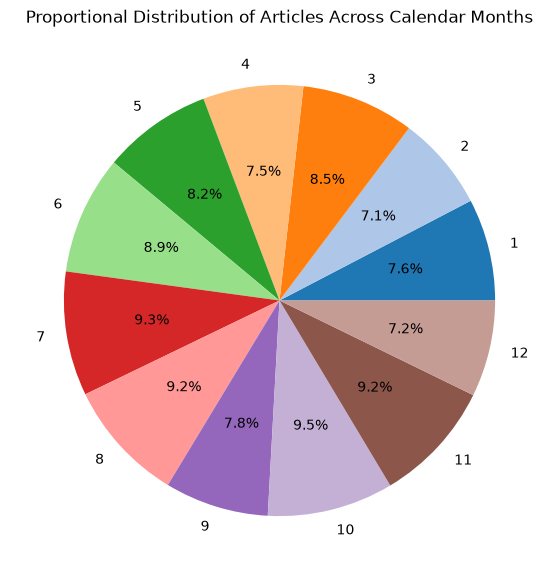

Chronological Frequency Table:
Month
1     55
2     51
3     61
4     54
5     59
6     64
7     67
8     66
9     56
10    68
11    66
12    52
Name: count, dtype: int64

Month with highest activity (Max): 10
Month with lowest activity (Min): 2


In [3]:
# Create a localized deep copy to isolate mutation
df_temporal = data.copy()

# Enforce standard datetime parsing
df_temporal["Date"] = pd.to_datetime(df_temporal["Date"], format="%d/%m/%Y")
df_temporal["Month"] = df_temporal["Date"].dt.month

# Compute categorical frequencies sorted chronologically
monthly_distribution = df_temporal["Month"].value_counts().sort_index()

# Extract boundary anomalies
max_month = monthly_distribution.idxmax()
min_month = monthly_distribution.idxmin()

# Data Visualization: Categorical Distribution
plt.figure(figsize=(7, 7))
plt.pie(monthly_distribution, labels=monthly_distribution.index, autopct='%1.1f%%', colors=plt.cm.tab20.colors)
plt.title("Proportional Distribution of Articles Across Calendar Months")
plt.show()

print("Chronological Frequency Table:")
print(monthly_distribution)
print(f"\nMonth with highest activity (Max): {max_month}\nMonth with lowest activity (Min): {min_month}")

## Text Metrics: Word Count Distribution

### Analytical Questions:
* **What is the distribution layout of article lengths measured in total words?**
* **What is the overall average (mean) word count across the entire corpus?**

Mean article word length: 290.73 words


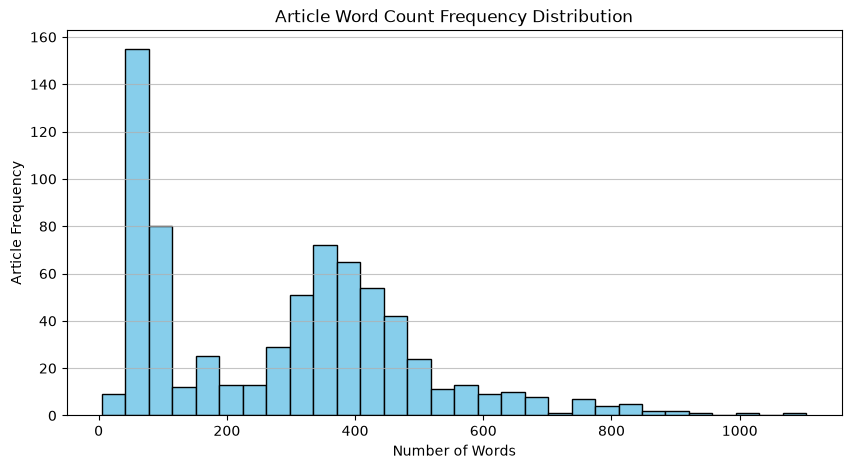

Frequency Segmentation by Fixed Ranges:
(-0.001, 200.0]    288
(200.0, 400.0]     222
(400.0, 600.0]     161
(600.0, 800.0]      35
(800.0, 1000.0]     11
(1000.0, inf]        2
Name: count, dtype: int64


In [4]:
df_length = data.copy()

def calculate_word_count(row):
    # Safely guard against potential null strings during evaluation
    return len(str(row["Content"]).split())

# Apply vectorized feature engineering
df_length["Total_Words"] = df_length.apply(calculate_word_count, axis=1)

# Compute descriptive statistics
mean_word_count = df_length["Total_Words"].mean()
print(f"Mean article word length: {mean_word_count:.2f} words")

# Data Visualization: Frequency Distribution Histogram
plt.figure(figsize=(10, 5))
plt.hist(df_length["Total_Words"], bins=30, color="skyblue", edgecolor="black")
plt.title("Article Word Count Frequency Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Article Frequency")
plt.grid(axis='y', alpha=0.75)
plt.show()

# Segment metric tracking into clean operational intervals
print("Frequency Segmentation by Fixed Ranges:")
print(df_length["Total_Words"].value_counts(bins=[0, 200, 400, 600, 800, 1000, float('inf')]).sort_index())


## Linguistic Analysis: Term Frequency-Inverse Document Frequency Base

### Analytical Questions:
* **What are the top 10 most frequent words appearing across the extracted text payloads?**

In [5]:
df_words = data.copy()

# Coalesce text entries into a unified lower-case tokens sequence
all_tokens = " ".join(df_words["Content"].dropna()).lower().split()

# Compute aggregate word frequencies
word_series = pd.Series(all_tokens)
top_frequencies = word_series.value_counts()

print("Top 10 Raw Term Frequencies across the entire Corpus:")
print(top_frequencies.head(10))


Top 10 Raw Term Frequencies across the entire Corpus:
u         24579
tu         5796
ku         4530
ti’        4488
le         3998
yéetel     3974
ti’al      3255
tumen      3086
yaan       2539
ma’        2094
Name: count, dtype: int64


Junmúuch’ <strong style="color:red;">u</strong> íinjenieroilo’ob Google’ <strong style="color:red;">tu</strong> k’a’aytajo’ob <strong style="color:red;">le</strong> lunes máanika’,
<strong style="color:red;">u</strong> beetiko’ob jump’éel múuch’kabil. <br>
<strong style="color:red;">Le</strong> je’ela’ <strong style="color:red;">ma’</strong> jump’éel ba’al suuk <strong style="color:red;">u</strong> yúuchul ichil máaxo’ob <strong style="color:red;">ku</strong> meyajtiko’ob téeknolojia.

Un grupo de ingenieros de Google anunciaron el lunes que formaron un sindicato, <br> creando una inusual organización gremial en la industria de la tecnología.

 Tak walkila’ <strong style="color:red;">u</strong> beeta’al múuch’kabilo’ob <strong style="color:red;">tumen</strong> <strong style="color:red;">u</strong> ajmeyajil máako’ob téeknolojiae’ <strong style="color:red;">ma’</strong> jump’éel ba’al suuka’an <strong style="color:red;">u</strong> yu’ubali’, <br>
<strong style="color:red;">tumen</strong> ma’alo’ob <strong style="color:red;">u</strong> náajalo’ob <strong style="color:red;">yéetel</strong> <strong style="color:red;">yaan</strong> xan uláak’ bix <strong style="color:red;">u</strong> ts’a’abal áantaj ti’ob, <br> je’el bix <strong style="color:red;"> u</strong> tséentalo’ob sáansamal <strong style="color:red;">yéetel</strong> <strong style="color:red;">u</strong> ts’a’abal ba’al <strong style="color:red;">ti’al</strong> <strong style="color:red;">u</strong> bino’ob <strong style="color:red;">yéetel</strong> u suuto’ob <strong style="color:red;">ti’</strong> <strong style="color:red;">u</strong> meyajo’ob. 

Hasta ahora el sindicalismo no se ha arraigado entre los trabajadores de los sectores más exclusivos de la tecnología,<br>  que reciben abultados salarios y otras formas de compensación como comida gratis y transporte al trabajo. 

Español: https://www.lajornadamaya.mx/internacional/34746/ingenieros-forman-sindicato-en-google <br>
Maya: https://www.lajornadamaya.mx/k'iintsil/34797/u-iinjenieroilo-ob-googlee-tu-kaajsajo-ob-u-muuch-kabilo-ob-ti-al-u-yaanta-al-ajmeyajo-ob

## Geospatial Extraction: Geographic Metadata Analysis

### Analytical Questions:
* **What are the primary geographical origins or locations referenced in the articles?**
* **Are there definitive spatial distribution patterns within the publication log?**

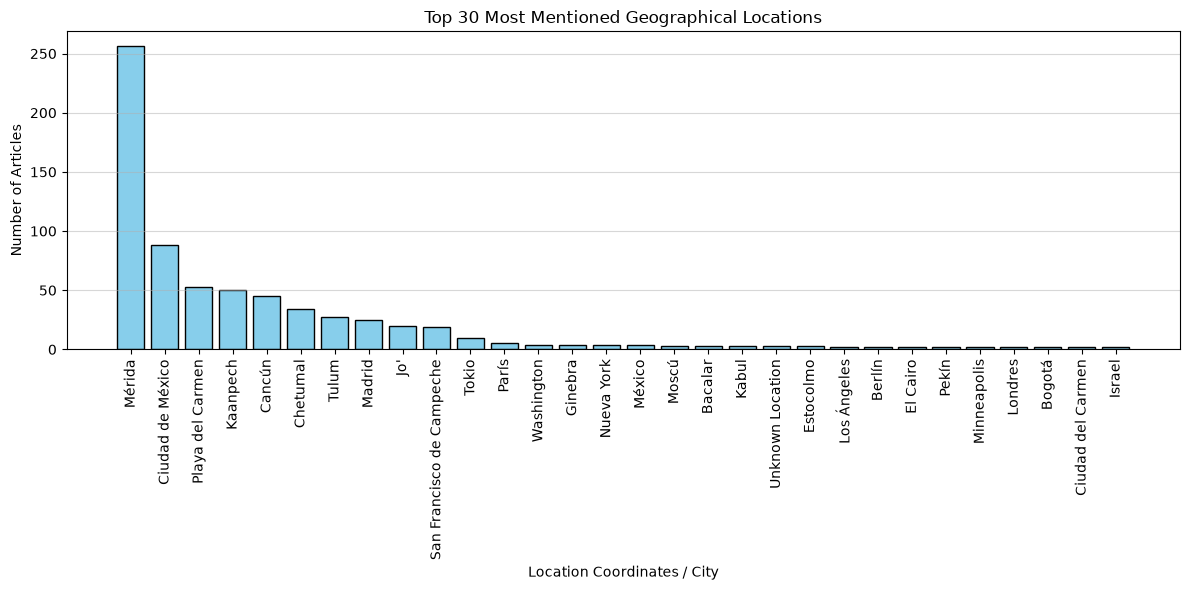

In [6]:
df_geo = data.copy()

def extract_primary_city(location_string):
    # Standardize string boundaries and slice out hierarchical regional chains
    return str(location_string).split(",")[0].strip()

# Transform location features
df_geo["Clean_Location"] = df_geo["Location"].apply(extract_primary_city)
top_locations = df_geo["Clean_Location"].value_counts().head(30)

# Data Visualization: Top Geographic Origins Bar Chart
plt.figure(figsize=(12, 6))
plt.bar(top_locations.index, top_locations.values, color="skyblue", edgecolor="black")
plt.title("Top 30 Most Mentioned Geographical Locations")
plt.xlabel("Location Coordinates / City")
plt.ylabel("Number of Articles")
plt.xticks(rotation=90)
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

## Bilingual Parsing: Spanish vs. Yucatec Maya Computational Text Segmentation

### Analytical Questions:
* **What proportion of words within a given sample text layer belongs to the Yucatec Maya language?**
* **What proportion of tokens maps directly to standard Spanish vocabulary?**
* **Are there overlaps or tokens that exist concurrently across both language schemas?**

In [ ]:
# Function definitions for advanced text profile matching
def generate_ngrams(text, n=3):
    text = text.lower()
    text = ''.join([c for c in text if c.isalpha() or c.isspace()])
    ngrams = [text[i:i+n] for i in range(len(text)-n+1)]
    return Counter(ngrams)

def load_text_from_file(file_name):
    # Resolve relative routing using the managed data directory handle
    target_path = DATA_DIR / file_name
    with open(target_path, 'r', encoding='utf-8') as file:
        return file.read()

# Load linguistic validation corpora
maya_corpus = load_text_from_file('maya_corpus.txt')
spanish_corpus = load_text_from_file('spanish_corpus.txt')

# Build static Language Profiles utilizing character 3-Grams
language_profiles = {
    'maya': generate_ngrams(maya_corpus, n=3),
    'es': generate_ngrams(spanish_corpus, n=3)
}

def proportion_similarity(target_profile, reference_profile):
    intersection = set(target_profile.keys()) & set(reference_profile.keys())
    matched_instances = sum(target_profile[ngram] for ngram in intersection)
    total_instances = sum(target_profile.values())
    return matched_instances / total_instances if total_instances > 0 else 0.0

def detect_text_language(text_payload):
    target_profile = generate_ngrams(text_payload, n=3)
    similarities = {lang: proportion_similarity(target_profile, ref_profile) for lang, ref_profile in language_profiles.items()}
    assigned_language = max(similarities, key=similarities.get)
    return assigned_language, similarities

# Execute profile evaluation sample
sample_text = data["Content"].iloc[0] if len(data) > 0 else ""
if sample_text:
    detected_lang, assessment_scores = detect_text_language(sample_text)
    print(f"Statistical Language Classification: {detected_lang}")
    print(f"Similarity Mapping Matrix: {assessment_scores}")

Statistical Language Classification: maya
Similarity Mapping Matrix: {'maya': 0.820229158435401, 'es': 0.6056894508099565}


In [7]:
def load_spanish_dictionary(file_name):
    target_path = DATA_DIR / file_name
    with open(target_path, 'r', encoding='utf-8') as file:
        # Load dictionary hashes into an O(1) look-up hash-set structure
        return set(word.strip().lower() for word in file.readlines())

def segment_and_count_tokens(text_content, lookup_dict):
    maya_token_count = 0
    spanish_token_count = 0
    tokens = str(text_content).split()
    
    for token in tokens:
        # Standardize strings by stripping punctuation artifacts
        cleaned_token = token.strip('.,;!?()[]{}"').lower()
        if cleaned_token in lookup_dict:
            spanish_token_count += 1
        else:
            # Token does not exist within the Spanish dictionary; class designated to Maya layer
            maya_token_count += 1
            
    return maya_token_count, spanish_token_count

# Initialize hash structures
dictionary_reference = load_spanish_dictionary('spanish_dictionary.txt')

# Evaluate a localized execution sample
if len(data) > 10:
    target_sample = data["Content"].iloc[10]
    maya_total, spanish_total = segment_and_count_tokens(target_sample, dictionary_reference)
    
    print("Evaluation Target Snippet:")
    print(f"\"{target_sample[:150]}...\"\n")
    print(f"Computed Yucatec Maya Tokens: {maya_total}")
    print(f"Computed Spanish Tokens: {spanish_total}")

Evaluation Target Snippet:
"Kaanpech yéetel Yucatáne’ náach p’aatalo’ob ti’ Quintana Roo ikil u táakbesa’alo’ob ti’ fíinansiero ba’alo’ob. Le ts’ook lu’uma’ ti’ yaan tu ka’ kúuch..."

Computed Yucatec Maya Tokens: 365
Computed Spanish Tokens: 99
